# v2 — cross-sectional selection (and why the obvious version fails)

v1 holds **every** name whose EWMA funding-APR clears the θ-band, equal-weight. On the full
universe (~466 pairs) that is ~120 names at once, Sharpe ~1.5 — while v1 on the 5 majors scored ~6.
**Widening the universe should only ever help** (you can always reproduce the small book by picking
the same names), so losing Sharpe means the *selection/weighting is suboptimal*. This notebook shows
exactly how, and fixes it.

Everything is booked through `lab.py`, which reproduces the production `engine.run` to 1e-6 — so
these research numbers equal what the strategy code produces.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREEN,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#2d6a4f','0.6'
COSTS = cfg.load_config('strategies/funding_carry/v2.1.yaml')['costs']
maj, non = H.universe(); MAJ = set(maj)
P = H.load_panels(maj + non)                     # F (funding), L (basis return), basis (level), E, R
F, L = P['F'], P['L']
par = H.validate_engine()
print('engine parity:', 'OK' if par['ok'] else 'MISMATCH', '| universe:', len(P['symbols']),
      f'names ({len(maj)} majors + {len(non)} others)')

def kpi(res):
    a, b = res['1.0x'], res['2.0x']
    return {'net%': round(a['ann_return']*100,1), 'Sharpe': a['sharpe'],
            'net@2x%': round(b['ann_return']*100,1), 'Sh@2x': b['sharpe'],
            'maxDD%': round(a['max_drawdown']*100,1), 'turn': round(a['ann_turnover'],0),
            'names': round(a['avg_names_held'],0)}
def eq(res): return res['net'].cumsum()*100     # cumulative net %

V1      = H.evaluate(P, 7, 0.08, 0.02, COSTS, warmup_days=30)
V2_TOPK = H.evaluate_v2(P, 7, 0.08, 0.02, 15, 25, 0.75, 0.40, COSTS, warmup_days=30)  # concentration
V2_0    = H.evaluate_v2(P, 7, 0.08, 0.02, None, None, 0.75, 0.40, COSTS, warmup_days=30)  # breadth
BASIS_VETO = [{'feature':'funding_vol','direction':'max','cap':0.75},
              {'feature':'neg_freq','direction':'max','cap':0.40},
              {'feature':'basis','direction':'max','cap':0.01}]
BASIS_SPECS = [{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
V2_1    = H.evaluate_select(P, 7,0.08,0.02, None,None, COSTS, feature_specs=BASIS_SPECS,
                            veto_rules=BASIS_VETO, warmup_days=30)                     # v2.1 basis veto
INVVOL  = H.evaluate_select(P, 7,0.08,0.02, None,None, COSTS, size_kind='inv_basis_vol', warmup_days=30)

2026-07-01 16:43:44,083 INFO     funding_carry.engine | funding_carry v1: net@1x ann=9.41% sharpe=6.41 turnover=9.1x (C:\Users\SamuelAhou\Documents\operator\results\funding_carry\v1\20260701T144344Z)


engine parity: OK | universe: 466 names (5 majors + 461 others)


## 1. The naive thesis fails

Rank all names by funding APR and hold the **top-K** (concentrate on the juiciest carry). It should
beat the diluted whole-band. It does the opposite — worse Sharpe and a **−43% drawdown**.

                                  net%  Sharpe  net@2x%  Sh@2x  maxDD%  turn  names
v1 whole-band                     15.9   1.530     13.0  1.245    -9.7  15.0  122.0
v2.0 top-K(15)                    12.0   0.454      3.6  0.135   -42.8  44.0   17.0
v2.0 breadth (band+funding-veto)  16.1   1.559     12.5  1.207    -8.4  19.0  118.0


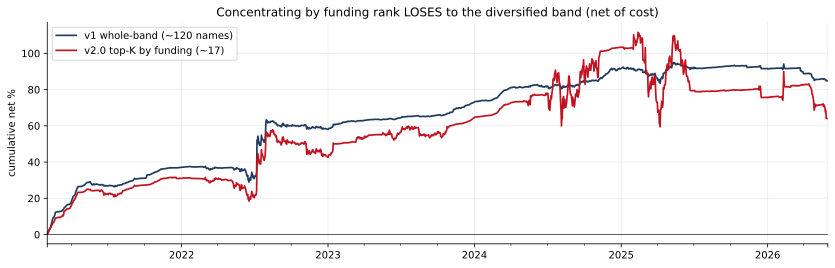

In [2]:
tab = pd.DataFrame({'v1 whole-band': kpi(V1), 'v2.0 top-K(15)': kpi(V2_TOPK),
                    'v2.0 breadth (band+funding-veto)': kpi(V2_0)}).T
print(tab.to_string())
fig, ax = plt.subplots(figsize=(14,4))
for lab_,res,c in [('v1 whole-band (~120 names)',V1,NAVY),('v2.0 top-K by funding (~17)',V2_TOPK,RED)]:
    eq(res).plot(ax=ax, color=c, lw=1.7, label=lab_)
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %'); ax.legend()
ax.set_title('Concentrating by funding rank LOSES to the diversified band (net of cost)')
plt.show()

## 2. Attribution — it's basis, not funding

Split the top-K book's gross P&L into **funding collected** vs **basis** (the delta-neutral leg
`r_spot − r_perp`) per year. Funding is positive every year; the damage is a **basis** crater
(2025). Concentration threw away the diversification that averages idiosyncratic basis moves to
zero.

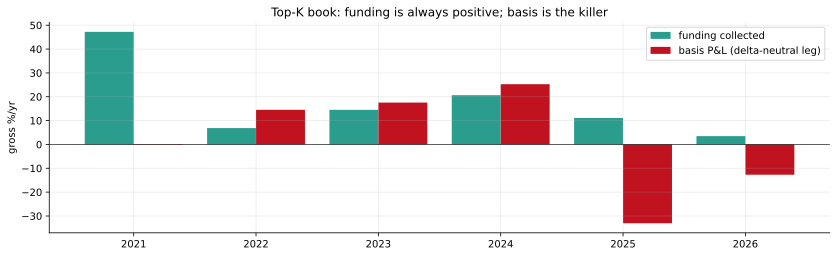

      funding_%  basis_%
year                    
2021       47.2     -0.2
2022        6.9     14.5
2023       14.5     17.6
2024       20.7     25.3
2025       11.1    -33.1
2026        3.5    -12.7


In [3]:
W = V2_TOPK['W']; pos = W.shift(1).fillna(0.0)
fund_y = (pos*F.fillna(0)).sum(axis=1); basis_y = (pos*L.fillna(0)).sum(axis=1)
rows = []
for y in range(2021, 2027):
    f = fund_y[fund_y.index.year==y].sum()*100; b = basis_y[basis_y.index.year==y].sum()*100
    if fund_y.index.year.isin([y]).any(): rows.append((y, f, b))
at = pd.DataFrame(rows, columns=['year','funding_%','basis_%']).set_index('year')
x = np.arange(len(at)); w = 0.4
fig, ax = plt.subplots(figsize=(14,3.8))
ax.bar(x-w/2, at['funding_%'], w, color=TEAL, label='funding collected')
ax.bar(x+w/2, at['basis_%'], w, color=RED, label='basis P&L (delta-neutral leg)')
ax.axhline(0,color='k',lw=0.6); ax.set_xticks(x); ax.set_xticklabels(at.index)
ax.set_ylabel('gross %/yr'); ax.legend(); ax.set_title('Top-K book: funding is always positive; basis is the killer')
plt.show(); print(at.round(1).to_string())

## 3. Diagnosis — why the wide universe underperforms

Three facts. **(a)** The majors rank ~100–150th by funding APR — their carry is *mediocre*, so any
top-K-by-funding **structurally excludes them**. **(b)** Yet the majors are the **cleanest-basis**
names (lowest basis-return vol). **(c)** Equal-weighting hands every band name 1/N regardless of
risk, so the high-basis-vol tail dominates portfolio variance.

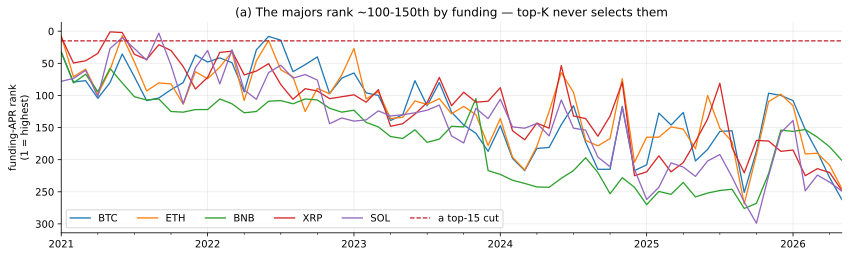

In [4]:
# (a) majors' cross-sectional funding-APR rank over time (of all live names that day)
A = H.signal_apr(F, 7).where(P['E'])
rank = A.rank(axis=1, ascending=False)
fig, ax = plt.subplots(figsize=(14,3.8))
for s in maj:
    rank[s].resample('MS').median().plot(ax=ax, lw=1.3, label=s.replace('usdt','').upper())
ax.axhline(15, color=RED, ls='--', lw=1.2, label='a top-15 cut')
ax.invert_yaxis(); ax.set_ylabel('funding-APR rank\n(1 = highest)'); ax.legend(ncol=6)
ax.set_title('(a) The majors rank ~100-150th by funding — top-K never selects them')
plt.show()

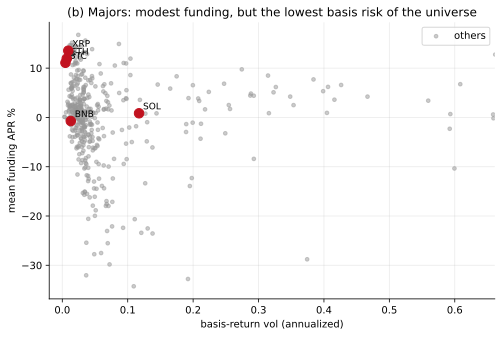

majors median basis-vol 0.009 vs universe median 0.034 (p90 0.291)
corr(funding APR, basis-vol) across names: -0.00  (so high funding does NOT even buy you low risk)


In [5]:
# (b) per-name funding APR vs basis-return vol; majors flagged
apr = (F.mean()*365*100).rename('apr'); bvol = (L.std()*np.sqrt(365)).rename('bvol')
d = pd.concat([apr, bvol], axis=1).dropna()
fig, ax = plt.subplots(figsize=(8,5))
oth = d.loc[[s for s in d.index if s not in MAJ]]
ax.scatter(oth['bvol'], oth['apr'], s=14, color=GREY, alpha=0.5, label='others')
for s in maj:
    if s in d.index:
        ax.scatter(d.loc[s,'bvol'], d.loc[s,'apr'], s=90, color=RED, zorder=5)
        ax.annotate(s.replace('usdt','').upper(), (d.loc[s,'bvol'], d.loc[s,'apr']),
                    fontsize=9, xytext=(4,4), textcoords='offset points')
ax.set_xlabel('basis-return vol (annualized)'); ax.set_ylabel('mean funding APR %')
ax.set_xlim(-0.02, min(1.0, d['bvol'].quantile(.95))); ax.legend()
ax.set_title('(b) Majors: modest funding, but the lowest basis risk of the universe')
plt.show()
print(f"majors median basis-vol {d.loc[[s for s in maj if s in d.index],'bvol'].median():.3f} "
      f"vs universe median {d['bvol'].median():.3f} (p90 {d['bvol'].quantile(.9):.3f})")
print(f"corr(funding APR, basis-vol) across names: {d['apr'].corr(d['bvol']):.2f}  "
      f"(so high funding does NOT even buy you low risk)")

## 4. The fix — treat basis risk (veto it, or size by it)

Two structural fixes, both keeping the diversified breadth: **veto** names whose basis is dislocated
(>1%), or **weight by 1/basis-vol** (risk-parity on the basis leg, no name dropped). Either recovers
most of the majors' Sharpe on the full universe.

                                net%  Sharpe  net@2x%  Sh@2x  maxDD%  turn  names
v1 whole-band                   15.9   1.530     13.0  1.245    -9.7  15.0  122.0
v2.0 breadth+funding-veto       16.1   1.559     12.5  1.207    -8.4  19.0  118.0
v2.1 +basis veto (|b|<1%)       10.4   5.404      6.6  3.365    -2.6  20.0  114.0
inv-basis-vol weight (v3 idea)  10.1   5.272      5.7  2.823    -2.2  23.0  122.0


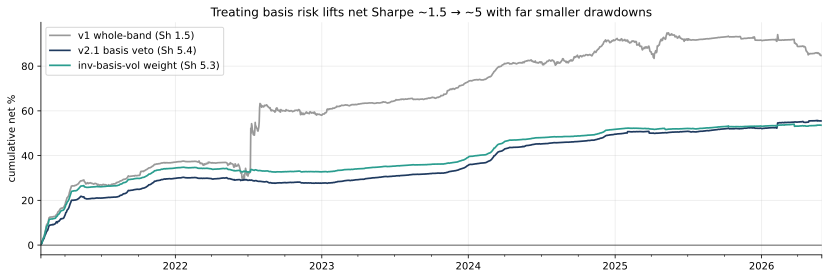

In [6]:
tab = pd.DataFrame({'v1 whole-band': kpi(V1), 'v2.0 breadth+funding-veto': kpi(V2_0),
                    'v2.1 +basis veto (|b|<1%)': kpi(V2_1),
                    'inv-basis-vol weight (v3 idea)': kpi(INVVOL)}).T
print(tab.to_string())
fig, ax = plt.subplots(figsize=(14,4.2))
for lab_,res,c in [('v1 whole-band',V1,GREY),('v2.1 basis veto',V2_1,NAVY),
                   ('inv-basis-vol weight',INVVOL,TEAL)]:
    eq(res).plot(ax=ax, color=c, lw=1.7, label=f"{lab_} (Sh {res['1.0x']['sharpe']:.1f})")
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %'); ax.legend()
ax.set_title('Treating basis risk lifts net Sharpe ~1.5 → ~5 with far smaller drawdowns')
plt.show()

## 5. Validation — robust, not a 2025 artifact

By-year Sharpe, and a temporal train/test split (tune-free — these are structural risk controls,
not fitted knobs). The fixes beat v1 in almost every year and, critically, **hold out of sample**
(inverse-vol weighting barely decays: train→test Sharpe ~5.8→5.1).

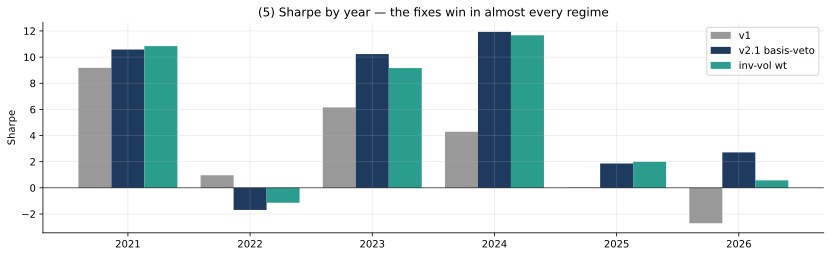

Temporal split (train 2021-2023 → held-out test 2024-2026):
                 train Sh  train net%  TEST Sh  TEST net%  TEST DD%
v1 whole-band       1.913        25.0    0.872        4.9      -9.7
v2.1 basis-veto     5.883        12.2    4.778        8.3      -0.9
inv-vol wt          5.750        13.4    5.131        6.0      -0.9


In [7]:
def by_year(res): return {int(y): v['sharpe'] for y,v in res['1.0x']['by_year'].items()}
yv = pd.DataFrame({'v1': by_year(V1), 'v2.1 basis-veto': by_year(V2_1),
                   'inv-vol wt': by_year(INVVOL)})
x = np.arange(len(yv)); w = 0.27
fig, ax = plt.subplots(figsize=(14,3.8))
for i,(c,col) in enumerate([('v1',GREY),('v2.1 basis-veto',NAVY),('inv-vol wt',TEAL)]):
    ax.bar(x+(i-1)*w, yv[c].values, w, color=col, label=c)
ax.axhline(0,color='k',lw=0.6); ax.set_xticks(x); ax.set_xticklabels(yv.index)
ax.set_ylabel('Sharpe'); ax.legend(); ax.set_title('(5) Sharpe by year — the fixes win in almost every regime')
plt.show()

DID = P['didx']; tr = H._window_mask(DID, end='2023-12-31'); te = H._window_mask(DID, start='2024-01-01')
def split(mk_res):
    a = mk_res(tr)['1.0x']; b = mk_res(te)['1.0x']
    return {'train Sh': a['sharpe'], 'train net%': round(a['ann_return']*100,1),
            'TEST Sh': b['sharpe'], 'TEST net%': round(b['ann_return']*100,1), 'TEST DD%': round(b['max_drawdown']*100,1)}
oos = pd.DataFrame({
    'v1 whole-band': split(lambda m: H.evaluate(P,7,0.08,0.02,COSTS,mask=m,warmup_days=30)),
    'v2.1 basis-veto': split(lambda m: H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=BASIS_SPECS,veto_rules=BASIS_VETO,mask=m,warmup_days=30)),
    'inv-vol wt': split(lambda m: H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,size_kind='inv_basis_vol',mask=m,warmup_days=30)),
}).T
print('Temporal split (train 2021-2023 → held-out test 2024-2026):'); print(oos.to_string())

## Takeaways

- **Widening the universe did not help because the *rules* were wrong, not the universe** — exactly
  as theory says it must be. The funding score ranks the clean majors ~110th, and equal-weight lets
  a ~19% toxic-basis tail dominate variance.
- **v2.1 = basis-blowout veto** (`config/strategies/funding_carry/v2.1.yaml`): net Sharpe **1.5 → 5.4**,
  max DD **−10% → −3%**, still Sharpe ~3.4 at 2× cost; robust across years and out-of-sample. This is
  the committed next version.
- **Inverse-basis-vol weighting** is the single most OOS-robust lever (test-period Sharpe ~5.1, DD
  ~−1%) and needs no veto — it is the natural **v3 (risk-aware sizing)** step; it requires `decide` to
  emit non-equal weights from the `basis_vol` feature the engine already builds.
- Caveats: gross-of-slippage-capacity; caps/knobs are conservative not optimized (validate held-out
  before trusting magnitudes); returns fall (16%→10%) as we stop over-betting high-vol names — the
  point is risk-adjusted return, not raw yield.